# ML Workflow

  Dataset
    →
  Understand columns
    →
  Clean data
    →
  Handle missing values
    →
  EDA
    →
  Identify target column
    →
  Separate X and y
    →
  Encode categorical columns
    →
  Train/Test Split
    →
  Feature Scaling (if required)
    →
  Train ML model
    →
  Prediction
    →
  Evaluate model

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_table("/content/affairs.csv",sep=",")

In [4]:
df.head()

,Unnamed: 0,rate_marriage,age,yrs_married,children,religious,educ,occupation,occupation_husb,affairs
0,0,3.0,32.0,9.0,3.0,3.0,17.0,2.0,5.0,0.111111
1,1,3.0,27.0,13.0,3.0,1.0,14.0,3.0,4.0,3.230769
2,2,4.0,22.0,2.5,0.0,1.0,16.0,3.0,5.0,1.400000
3,3,4.0,37.0,16.5,4.0,3.0,16.0,5.0,5.0,0.727273
4,4,5.0,27.0,9.0,1.0,1.0,14.0,3.0,4.0,4.666666


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6366 entries, 0 to 6365
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       6366 non-null   int64  
 1   rate_marriage    6366 non-null   float64
 2   age              6366 non-null   float64
 3   yrs_married      6366 non-null   float64
 4   children         6366 non-null   float64
 5   religious        6366 non-null   float64
 6   educ             6366 non-null   float64
 7   occupation       6366 non-null   float64
 8   occupation_husb  6366 non-null   float64
 9   affairs          6366 non-null   float64
dtypes: float64(9), int64(1)
memory usage: 497.5 KB


In [6]:
df.describe()

,Unnamed: 0,rate_marriage,age,yrs_married,children,religious,educ,occupation,occupation_husb,affairs
count,6366.000000,6366.000000,6366.000000,6366.000000,6366.000000,6366.000000,6366.000000,6366.000000,6366.000000,6366.000000
mean,3182.500000,4.109645,29.082862,9.009425,1.396874,2.426170,14.209865,3.424128,3.850141,0.705374
std,1837.850239,0.961430,6.847882,7.280120,1.433471,0.878369,2.178003,0.942399,1.346435,2.203374
min,0.000000,1.000000,17.500000,0.500000,0.000000,1.000000,9.000000,1.000000,1.000000,0.000000
25%,1591.250000,4.000000,22.000000,2.500000,0.000000,2.000000,12.000000,3.000000,3.000000,0.000000
50%,3182.500000,4.000000,27.000000,6.000000,1.000000,2.000000,14.000000,3.000000,4.000000,0.000000
75%,4773.750000,5.000000,32.000000,16.500000,2.000000,3.000000,16.000000,4.000000,5.000000,0.484848
max,6365.000000,5.000000,42.000000,23.000000,5.500000,4.000000,20.000000,6.000000,6.000000,57.599991


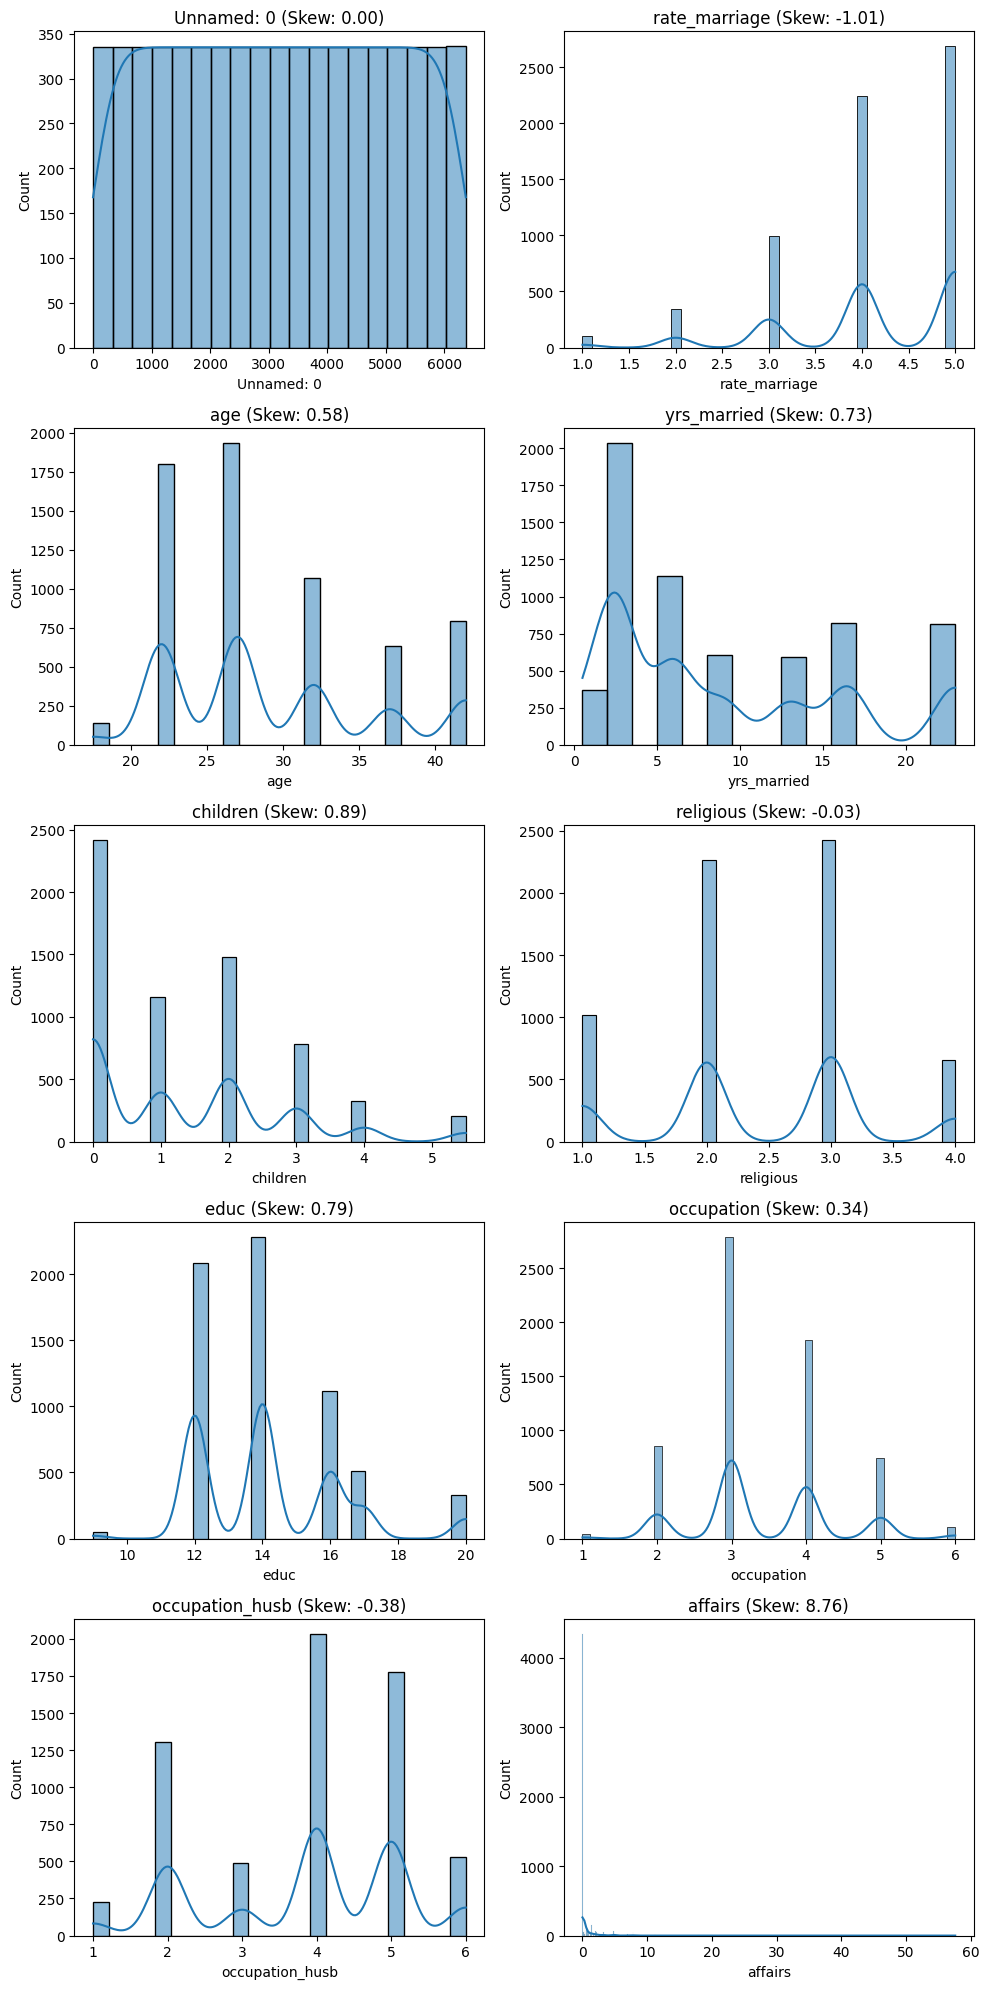

In [7]:
fig, axis = plt.subplots(5,2, figsize=(10,20))
for col, ax in zip(df.columns, axis.flatten()):
    sns.histplot(df[col], kde=True, ax=ax)
    if pd.api.types.is_numeric_dtype(df[col]):
        ax.set_title(f"{col} (Skew: {df[col].skew():.2f})")
    else:
        ax.set_title(f"{col} (Categorical)")
plt.tight_layout()
plt.show()

In [8]:
for i in df.columns:
  df[i]=np.log1p(df[i])

<Axes: xlabel='affairs', ylabel='Density'>

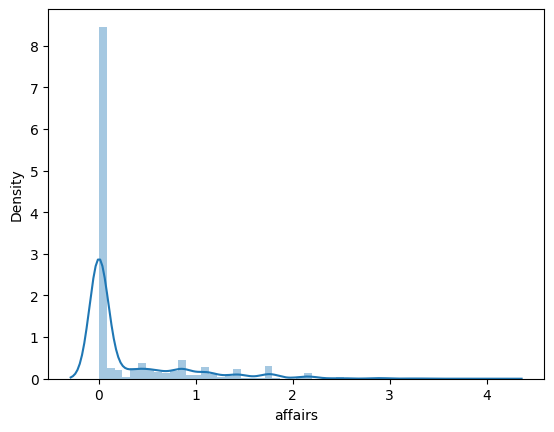

In [9]:
sns.distplot(df['affairs'])

<Axes: >

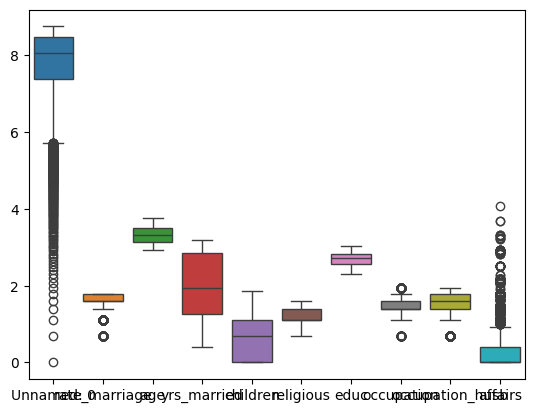

In [10]:
sns.boxplot(df)

In [11]:
%pip install outlier-tool-shashikant

In [12]:
from outlier_tool import Outliers
o = Outliers(df)

In [13]:
o.find("iqr")

,column,method,lower,upper,outliers,percent
0,Unnamed: 0,iqr,5.725613,10.118387,306,4.81
1,rate_marriage,iqr,1.335956,2.065242,447,7.02
2,age,iqr,2.593974,4.038028,0,0.00
3,yrs_married,iqr,-1.161394,5.276358,0,0.00
4,children,iqr,-1.647918,2.746531,0,0.00
5,religious,iqr,0.667089,1.817817,0,0.00
6,educ,iqr,2.162553,3.235609,0,0.00
7,occupation,iqr,1.051579,1.944153,150,2.36
8,occupation_husb,iqr,0.778097,2.399957,229,3.60
9,affairs,iqr,-0.592969,0.988282,750,11.78


In [14]:
df1= o.iqr_cap()

<Axes: ylabel='affairs'>

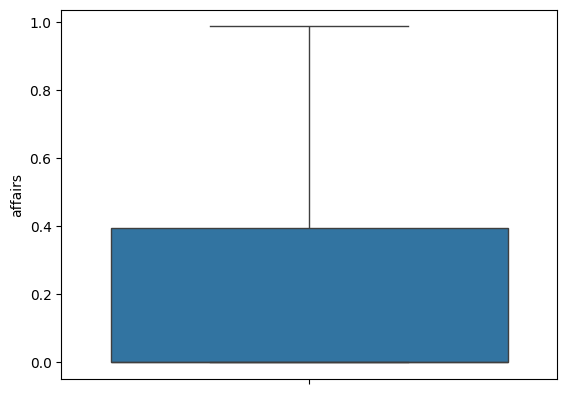

In [15]:
sns.boxplot(df1['affairs'])

In [16]:
X = df1.iloc[ : , :-1]
Y = df1.iloc[ : , -1]

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [18]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
DTR = DecisionTreeRegressor()
DTR.fit(X_train, Y_train)
y_prid = DTR.predict(X_test)
r2 = r2_score(Y_test, y_prid)
print(f"R2 Score: {r2}")
train = DTR.score(X_train, Y_train)
test = DTR.score(X_test, Y_test)
print(f"Train Score: {train}")
print(f"Test Score: {test}")

R2 Score: 0.5537458821101298
Train Score: 0.9997893780543605
Test Score: 0.5537458821101298


In [19]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
DTR = DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42)
DTR.fit(X_train, Y_train)
y_prid = DTR.predict(X_test)
r2 = r2_score(Y_test, y_prid)
print(f"R2 Score: {r2}")
train = DTR.score(X_train, Y_train)
test = DTR.score(X_test, Y_test)
print(f"Train Score: {train}")
print(f"Test Score: {test}")

R2 Score: 0.7623189758088222
Train Score: 0.8065855551900962
Test Score: 0.7623189758088222


In [20]:
new = {}
for col in X.columns:
    value = input(f"Enter {col}: ")
    # All features in X are numeric, and np.log1p was applied in a previous step
    new[col] = [np.log1p(float(value))]

new_df = pd.DataFrame(new)

# Make prediction using the trained DecisionTreeRegressor (DTR)
predicted_affairs_log = DTR.predict(new_df)[0]

# Inverse transformation of log1p to get the actual affairs prediction
predicted_affairs = np.expm1(predicted_affairs_log)

print(f"\t Predicted affairs (original scale): {predicted_affairs:.4f}")

Enter Unnamed: 0: 215
Enter rate_marriage: 2
Enter age: 25
Enter yrs_married: 3
Enter children: 0
Enter religious: 1
Enter educ: 1
Enter occupation: 0
Enter occupation_husb: 3

	 Predicted affairs (scaled log1p): 0.8868
	 Predicted affairs (original scale): 1.4274
